In [1]:
import os
import glob
import pandas as pd
import rasterio
import numpy as np

In [2]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [3]:
data_path = "/content/drive/MyDrive/big_data_project"

In [4]:
from rasterio.plot import show

import matplotlib.pyplot as plt

tif_path = r"Data/soil/HWSD2_RASTER/HWSD2.bil"
tif_path = os.path.join(data_path, tif_path)


In [5]:
!ls -l /content/drive/MyDrive/big_data_project/Data/soil/HWSD2_RASTER/

total 1822502
-rw------- 1 root root 1866240000 Nov 11  2022 HWSD2.bil
-rw------- 1 root root        338 Nov 11  2022 HWSD2.hdr
-rw------- 1 root root        146 Nov 11  2022 HWSD2.prj
-rw------- 1 root root         64 Nov 11  2022 HWSD2.stx


In [6]:
import os
size_gb = os.path.getsize(tif_path) / (1024**3)
print(f"Taille du fichier : {size_gb:.2f} GB")

Taille du fichier : 1.74 GB


In [7]:
with rasterio.open(tif_path) as ds:
    print(ds.count)

1


In [8]:
def preparer_donnees_soil():
   
    
    df_grille = pd.read_csv("/content/drive/MyDrive/big_data_project/Data/csv_final/grid_portugal_1km.csv")
    

    print(f"Grille: {len(df_grille)} points")
    
    
    df_complet = df_grille[['longitude', 'latitude']].copy()
    tif_path = os.path.join(data_path, r"Data/soil/HWSD2_RASTER/HWSD2.bil")   
    valeurs = extraction_vectorisee(tif_path, df_grille)
    df_complet["SMU_ID"] = valeurs
            
    valides = np.sum(~np.isnan(valeurs))
    print(f"({valides} valides)")
    
    # Sauvegarde
    output_csv = os.path.join(data_path, "Data/soil/donnees_soil_collab.csv")
    df_complet.to_csv(output_csv, index=False)
    
    return df_complet

# Version vectorisée à implémenter
def extraction_vectorisee(tif_path, df_points):
    with rasterio.open(tif_path) as src:
        # Conversion de TOUTES les coordonnées en une fois
        rows, cols = rasterio.transform.rowcol(
            src.transform, 
            df_points['longitude'].values, 
            df_points['latitude'].values
        )
        
        # Masque des points valides
        mask = (rows >= 0) & (rows < src.height) & (cols >= 0) & (cols < src.width)
        
        # Initialisation du tableau de résultats
        valeurs = np.full(len(df_points), np.nan)
        
        if np.any(mask):
            # Extraction des valeurs valides
            data = src.read(1)
            valeurs_valides = data[rows[mask], cols[mask]]
            
            # Application du masque
            valeurs[mask] = valeurs_valides
            
            # Gestion NoData
            valeurs[valeurs == src.nodata] = np.nan
    
    return valeurs

# Essayez cette version plus rapide
data = preparer_donnees_soil()

Grille: 89198 points
(89112 valides)


In [9]:
data.isna().sum()

,0
longitude,0
latitude,0
SMU_ID,86


In [10]:
data[data["SMU_ID"].isna()].head(86)

,longitude,latitude,SMU_ID
3,-8.952309,37.003139,NaN
9,-7.929930,37.005792,NaN
81,-8.885261,37.039625,NaN
1170,-7.546833,37.148687,NaN
1418,-8.909117,37.174628,NaN
...,...,...,...
69757,-8.655396,41.040236,NaN
71018,-8.667872,41.112214,NaN
71987,-8.692141,41.166125,NaN
73689,-8.728702,41.255984,NaN


In [11]:
from scipy.spatial import cKDTree

# Séparer les points valides et NaN
valid_mask = data["SMU_ID"].notna()
nan_mask = ~valid_mask

valid_coords = data.loc[valid_mask, ["longitude", "latitude"]].values
nan_coords = data.loc[nan_mask, ["longitude", "latitude"]].values
valid_values = data.loc[valid_mask, "SMU_ID"].values

# Construire l'arbre KD et trouver le plus proche voisin
tree = cKDTree(valid_coords)
_, idx = tree.query(nan_coords, k=1)

# Remplacer les NaN par la valeur la plus proche
data.loc[nan_mask, "SMU_ID"] = valid_values[idx]

In [12]:
data.isna().sum()

,0
longitude,0
latitude,0
SMU_ID,0


In [13]:
output_csv = "/content/drive/MyDrive/big_data_project/Data/soil/donnees_soil_1km_without_missing_valuesCollab.csv"
data.to_csv(output_csv, index=False)

In [14]:
!pip install pyodbc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 340.3/340.3 kB 6.8 MB/s eta 0:00:00a 0:00:01


In [15]:
from rasterio.enums import Resampling
import requests
import geopandas as gpd
from rasterio.mask import mask
from shapely.geometry import mapping
import pyodbc

In [16]:
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns

In [17]:
!ls -l /content/drive/MyDrive/big_data_project/Data/soil/HWSD2_RASTER/HWSD2.bil

-rw------- 1 root root 1866240000 Nov 11  2022 /content/drive/MyDrive/big_data_project/Data/soil/HWSD2_RASTER/HWSD2.bil


In [18]:

data_dir = r"/content/drive/MyDrive/big_data_project/Data/soil"
bil_path = os.path.join(data_dir, "HWSD2_RASTER/HWSD2.bil")
mdb_path = os.path.join(data_dir, "HWSD2.mdb")
fire_csv = r"/content/drive/MyDrive/big_data_project/Data/csv_final/grid_portugal_1km.csv"
shp_path = "/content/drive/MyDrive/big_data_project/Data/Land_Cover/landcover_portugal_300m.tif"
out_csv = os.path.join(data_dir, "soil_mergedCollab.csv")
smu_col = "HWSD2_SMU_ID"


fire_all = pd.read_csv(fire_csv)
fire_all.head()


,latitude,longitude,landcover
0,36.987823,-7.963676,210
1,36.994129,-8.952213,110
2,36.996850,-7.974890,210
3,37.003139,-8.952309,210
4,37.003216,-8.941076,210


In [19]:
!apt-get update -qq
!apt-get install -y mdbtools

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  libmdb3 libmdbsql3
Suggested packages:
  bash-completion
The following NEW packages will be installed:
  libmdb3 libmdbsql3 mdbtools
0 upgraded, 3 newly installed, 0 to remove and 39 not upgraded.
Need to get 136 kB of archives.
After this operation, 486 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/universe amd64 libmdb3 amd64 1.0.0+dfsg-1 [68.9 kB]
Get:2 http://archive.ubuntu.com/ubuntu jammy/universe amd64 libmdbsql3 amd64 1.0.0+dfsg-1 [18.8 kB]
Get:3 http://archive.ubuntu.com/ubuntu jammy/universe amd64 mdbtools amd64 1.0.0+dfsg-1 [48.3 kB]
Fetched 136 kB in 1s (236 kB/s)    
Selecting previously unselected

In [20]:
!ls /content/drive/MyDrive/big_data_project/Data/soil

donnees_soil_1km.csv				   HWSD2_LAYERS.csv
donnees_soil_1km_without_missing_valuesCollab.csv  HWSD2.mdb
donnees_soil_1km_without_missing_values.csv	   HWSD2_RASTER
donnees_soil_collab.csv				   HWSD2_SMUCollab_all.csv
HWSD2_clipped.tif				   HWSD2_SMU.csv
HWSD2_LAYERSCollab_all.csv


In [21]:
!pip install pandas_access

  Preparing metadata (setup.py) ... done
  Created wheel for pandas_access: filename=pandas_access-0.0.1-py3-none-any.whl size=4613 sha256=9c90b257f9e5f31ef3a6bd77b1f6110eed0bcacfa6a5d900c52ad1bb0cba13eb
  Stored in directory: /root/.cache/pip/wheels/73/25/a1/788f19e3497c7cd72ac8f052e4150c1401c4b8ebd0f22f5e65
Successfully built pandas_access


In [22]:
import numpy as np

# Correction de compatibilité pour NumPy 2.0+
if not hasattr(np, 'float_'):
    np.float_ = np.float64
if not hasattr(np, 'bool_'):
    np.bool_ = np.bool
# Si np.bool8 n'existe pas, on utilise np.bool_
if not hasattr(np, 'bool8'):
    np.bool8 = np.bool_

import pandas_access as mdb
import pandas as pd

In [23]:
import subprocess
import io

In [24]:
def charge_table_access(path, table_name):
    print(f"Extraction de la table {table_name}...")
    # On utilise mdb-export (installé via mdbtools) pour transformer le MDB en CSV texte
    process = subprocess.Popen(['mdb-export', path, table_name], 
                               stdout=subprocess.PIPE, stderr=subprocess.PIPE)
    stdout, stderr = process.communicate()
    
    if process.returncode != 0:
        print(f"❌ Erreur pour {table_name}: {stderr.decode()}")
        return None
    
    # On lit le CSV avec low_memory=False pour que Pandas accepte les colonnes mixtes (Entiers + NA)
    return pd.read_csv(io.BytesIO(stdout), low_memory=False)

# 3️⃣ Exécution
try:
    # Lecture de la table SMU
    df_smu2 = charge_table_access(mdb_path, "HWSD2_SMU")
    
    # Lecture de la table LAYERS (celle qui posait problème)
    df_layer2 = charge_table_access(mdb_path, "HWSD2_LAYERS")
    
    if df_smu2 is not None and df_layer2 is not None:
        print(f"Succès ! Taille SMU : {df_smu2.shape}")
        print(f"Succès ! Taille LAYERS : {df_layer2.shape}")
    else:
        print("Une ou plusieurs tables n'ont pas pu être chargées.")

except Exception as e:
    print(f"Erreur critique : {e}")

Extraction de la table HWSD2_SMU...
Extraction de la table HWSD2_LAYERS...
Succès ! Taille SMU : (29538, 23)
Succès ! Taille LAYERS : (408835, 48)


In [25]:
df_layer = df_layer2
df_smu = df_smu2

In [26]:
df_layer.head()

,ID,HWSD2_SMU_ID,NSC_MU_SOURCE1,NSC_MU_SOURCE2,WISE30s_SMU_ID,HWSD1_SMU_ID,COVERAGE,SEQUENCE,SHARE,NSC,...,CEC_SOIL,CEC_CLAY,CEC_EFF,TEB,BSAT,ALUM_SAT,ESP,TCARBON_EQ,GYPSUM,ELEC_COND
0,1,1666,NaN,NaN,WD10001666,1666,4,1,70,NaN,...,8,50,4,5,71,0,4,0.0,2.9,1
1,2,6309,NaN,NaN,WD10006309,6309,4,1,50,NaN,...,8,50,4,5,71,0,4,0.0,2.9,1
2,3,1700,NaN,NaN,WD10001700,1700,4,1,60,NaN,...,8,50,4,5,71,0,4,0.0,2.9,1
3,4,6310,NaN,NaN,WD10006310,6310,4,1,30,NaN,...,8,50,4,5,71,0,4,0.0,2.9,1
4,5,6311,NaN,NaN,WD10006311,6311,4,1,50,NaN,...,8,50,4,5,71,0,4,0.0,2.9,1


In [27]:
df_smu.head()

,ID,HWSD2_SMU_ID,WISE30s_SMU_ID,HWSD1_SMU_ID,COVERAGE,SHARE,WRB4,WRB_PHASES,WRB2,WRB2_CODE,...,REF_BULK_DENSITY,BULK_DENSITY,DRAINAGE,ROOT_DEPTH,AWC,PHASE1,PHASE2,ROOTS,IL,ADD_PROP
0,669,12707,WD10012707,12707,3,40,ALfr,ALfr,AL,2,...,1.63,1.35,MW,1,168,NaN,NaN,NaN,NaN,0.0
1,695,11825,WD30011825,11825,2,100,ALfr,ALfr,AL,2,...,1.76,1.44,MW,1,152,NaN,NaN,NaN,NaN,0.0
2,696,11823,WD30011823,11823,2,100,ALfr,ALfr,AL,2,...,1.76,1.44,MW,1,152,NaN,NaN,NaN,NaN,0.0
3,697,13458,WD30013458,13458,3,100,ALfr,ALfr,AL,2,...,1.76,1.44,MW,1,152,NaN,NaN,NaN,NaN,0.0
4,698,11824,WD30011824,11824,2,100,ALfr,ALfr,AL,2,...,1.76,1.44,MW,1,152,NaN,NaN,NaN,NaN,0.0


In [28]:
df_layer.to_csv("/content/drive/MyDrive/big_data_project/Data/soil/HWSD2_LAYERSCollab_all.csv", index=False)
df_smu.to_csv("/content/drive/MyDrive/big_data_project/Data/soil/HWSD2_SMUCollab_all.csv", index=False)

In [29]:
df_layer = pd.read_csv("/content/drive/MyDrive/big_data_project/Data/soil/HWSD2_LAYERS.csv")
df_smu = pd.read_csv("/content/drive/MyDrive/big_data_project/Data/soil/HWSD2_SMU.csv")

In [30]:
df_layer.shape

(1603, 48)

In [31]:

# Filtrer SMU présents dans le raster
unique_ids = np.unique(data[~np.isnan(data)]).astype(int)
df_smu= df_smu[df_smu[smu_col].isin(unique_ids)]


In [32]:

# Filtrer couche D1
df_layer_d1 = df_layer[df_layer["LAYER"].str.upper() == "D1"].copy()


In [33]:

# Sélection des colonnes existantes dans la couche D1
desired_cols = [
    smu_col, "LAYER", "COARSE", "SAND", "SILT", "CLAY",
    "TEXTURE_USDA", "TEXTURE_SOTER", "BULK", "REF_BULK", "ORG_CARBON",
    "PH_WATER", "TOTAL_N", "CN_RATIO", "CEC_SOIL", "CEC_CLAY", "CEC_EFF",
    "TEB", "BSAT", "ALUM_SAT", "ESP", "TCARBON_EQ", "GYPSUM", "ELEC_COND"
]
selected_features = [col for col in desired_cols if col in df_layer_d1.columns]
df_layer_d1 = df_layer_d1[selected_features]


In [34]:

# Merge complet pour obtenir df_joined
df_joined = pd.merge(df_smu[[smu_col]], df_layer_d1, on=smu_col, how="inner")
print(f"{len(df_joined)} D1-layer soil units matched with raster.")


229 D1-layer soil units matched with raster.


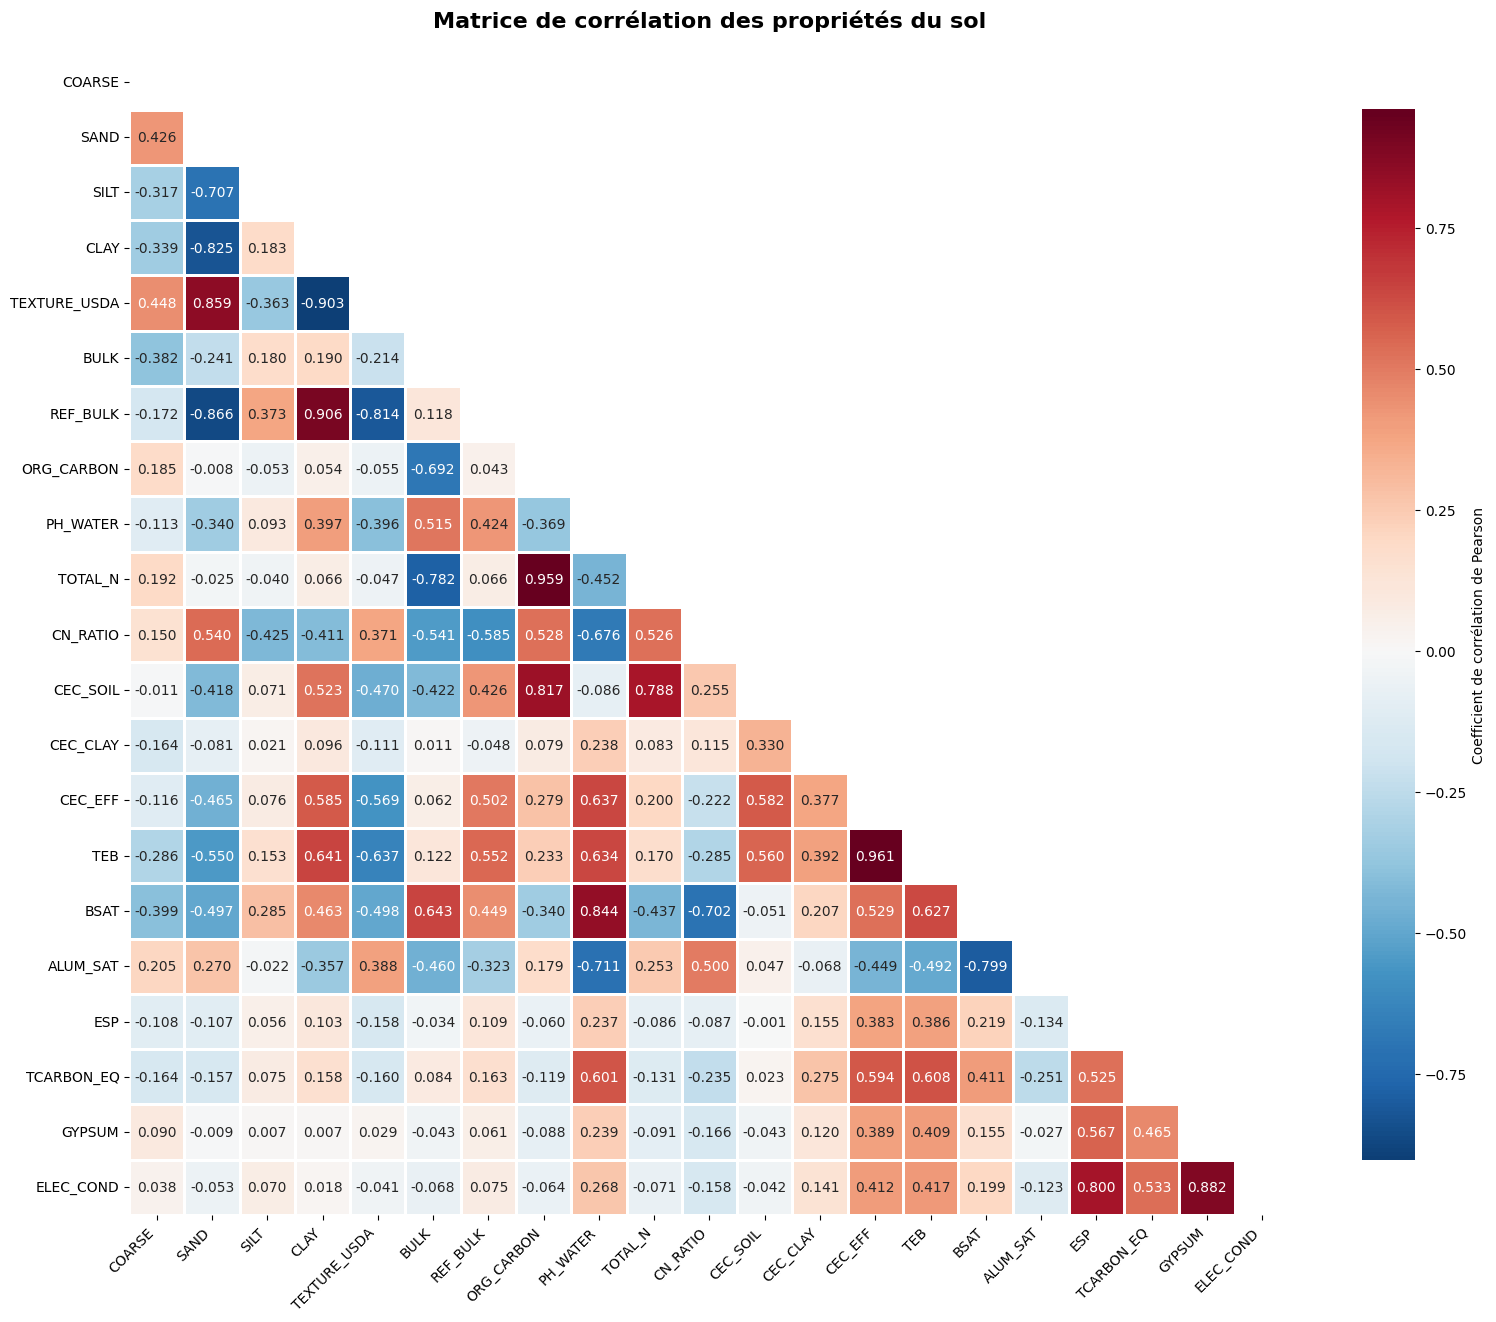

In [35]:


numeric_props = [col for col in df_joined.select_dtypes(include=[np.number]).columns if col != smu_col]

df_for_corr_clean = df_joined[numeric_props].dropna()
correlation_matrix = df_for_corr_clean.corr(method='pearson')

# Affichage heatmap complète
plt.figure(figsize=(16,14))
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
sns.heatmap(
    correlation_matrix,
    mask=mask,
    annot=True,
    fmt=".3f",
    cmap="RdBu_r",
    center=0,
    square=True,
    linewidths=1,
    linecolor='white',
    cbar_kws={"shrink":0.8, "label":"Coefficient de corrélation de Pearson"}
)
plt.title("Matrice de corrélation des propriétés du sol", fontsize=16, pad=20, weight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [36]:

threshold = 0.9
upper = correlation_matrix.where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool))
to_drop = [col for col in upper.columns if any(upper[col] > threshold)]
print("Features trop corrélées à supprimer :", to_drop)
df_soil_clean = df_joined.drop(columns=to_drop)


Features trop corrélées à supprimer : ['REF_BULK', 'TOTAL_N', 'TEB']


In [37]:
raster_path = "/content/drive/MyDrive/big_data_project/Data/soil/HWSD2_clipped.tif"
raster = rasterio.open(raster_path)

In [38]:

coords = [(lon, lat) for lon, lat in zip(fire_all["longitude"], fire_all["latitude"])]
smu_values = []
for val in tqdm(raster.sample(coords), total=len(coords), desc="Extraction SMU_ID"):
    smu_values.append(val[0])
fire_all["SMU_ID"] = smu_values


Extraction SMU_ID:   0%|          | 0/89198 [00:00<?, ?it/s]

Extraction SMU_ID: 100%|██████████| 89198/89198 [02:56<00:00, 505.96it/s]  


In [39]:

df_fire_soil = pd.merge(fire_all, df_soil_clean, left_on="SMU_ID", right_on=smu_col, how="left")

In [40]:
output_csv = r"/content/drive/MyDrive/big_data_project/Data/soil/soil_mergd_splited_with_sql.csv"

In [41]:
df_fire_soil.to_csv(out_csv, index=False)
print(f"\nCSV final des points feu avec propriétés du sol nettoyées sauvegardé : {out_csv}")


CSV final des points feu avec propriétés du sol nettoyées sauvegardé : /content/drive/MyDrive/big_data_project/Data/soil/soil_mergedCollab.csv


In [42]:
df = pd.read_csv("/content/drive/MyDrive/big_data_project/Data/soil/soil_mergedCollab.csv")

In [43]:
df_fire_soil.shape

(608947, 25)

In [44]:
df.shape

(608947, 25)